In [114]:
from anemone.inversion import *
from anemone.forwards import Forward, Forward2, logify_forward
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
from anemone.experiment import compute_relstd


logForward = logify_forward(Forward)

times = torch.logspace(-6,-2, 41)
fwrTD = Forward.example(times=times, tolerance=1e-6)

res_start = LogResistivity.smooth(torch.ones(31, dtype=torch.double)*100., torch.cumsum(torch.logspace(0.3,1,30), 0))
rho,thick = res_start.mod
rho[10:18] = 80.
rho[18:] = 30.
mod_true = LogResistivity.smooth(rho, torch.cumsum(thick,0))


dbdt_true = fwrTD(rho, thick)#.exp()
d_relerr = compute_relstd(fwrTD.times, dbdt_true, current=1.)
# d_err = torch.log1p(d_relerr)
d_err = dbdt_true * d_relerr
d_obs = dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr
# negatives = d_obs <= 0
# d_err[negatives] = 1e6

# d_obs = torch.abs(d_obs).log()

fastJac = fastjacobian(Tikhonov)

inv = fastJac(d_obs, d_err, res_start, fwrTD)
inv.data_misfit_acceptance_threshold = 0.9
res_mod = inv.invert(iter_cap=10)        


001	misfit:	1.04
002	misfit:	0.95
003	misfit:	0.93
004	misfit:	0.92
005	misfit:	0.91
006	misfit:	0.91
007	misfit:	0.91
008	misfit:	0.91
009	misfit:	0.90
010	misfit:	0.90
reached iteration cap..


In [115]:
# fwrTD = logForward.example(times=times, tolerance=1e-3)

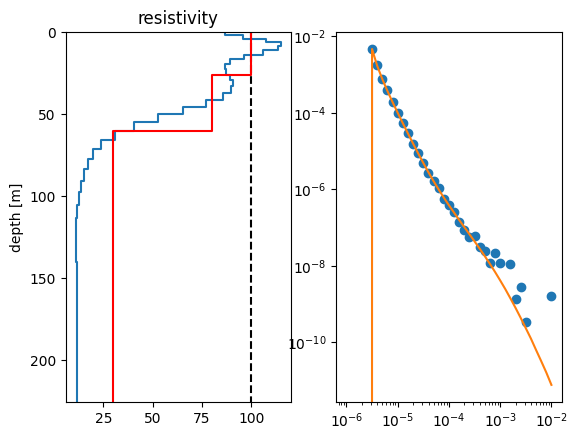

In [116]:
import matplotlib.pyplot as plt

fig,axs = plt.subplots(1,2)

ax = res_start.plot(axs=axs[:1], color='black', linestyle='--')
ax = res_mod.plot(axs=axs[:1])
mod_true.plot(axs=axs[:1], color='red', label='True model')

d_pred = fwrTD(*res_mod.mod)
axs[1].loglog(fwrTD.times, d_obs, 'o', label='Observed')
axs[1].loglog(fwrTD.times, d_pred, '-', label='Predicted')
plt.show()

In [117]:
def fwraugment(log_resistivity):
    res = torch.from_numpy(log_resistivity).exp()
    dbdt = fwrTD(res, res_start.thickness).numpy().T
    dM = np.diff(log_resistivity, axis=0)
    data = np.vstack([dbdt, dM])
    return data.T

In [118]:
import numpy as np
from numpy.linalg import inv
from time import perf_counter as timer

class EnsembleSmoother(fastJac):
    def __init__(self, data_observed, data_error, starting_model, forward_operator):
        super().__init__(data_observed, data_error, starting_model, forward_operator)
        
    def invert(self, n_sim=100, n_iter=4, log=print):
        if isinstance(n_sim, float):
            n_sim = int(n_sim)

        lbnds = self.model.lbnds.numpy()
        ubnds = self.model.ubnds.numpy()
        print(lbnds[0], ubnds[0])

        n_data=len(self.data_observed)
        n_mpar=len(self.model.vec)

        Csim = np.zeros((n_sim, n_mpar))
        data_sim = np.zeros((n_sim, n_data))
        for i in range(n_sim):
            tmp_mod = torch.from_numpy(np.random.uniform(lbnds, ubnds))
            Csim[i] = self.model.make_physical(tmp_mod).numpy()
            # data_sim[i] = self.mforward(Csim[i])
        data_sim = np.nan_to_num(fwraugment(Csim.T))
        self.Cstart = Csim.copy()

        # # # create vector of inflation coefficients such that
        # # # Σ (1 / α_i) = 1
        ralpha = 1./(np.arange(n_iter)+1)

        ralpha /= ralpha.sum()
        alpha_all = 1./ralpha


        noise = self.data_error
        Ce = np.diag(noise**2)
        Ce_sqrt = np.sqrt(Ce)

        tiled_data = np.nan_to_num(np.tile(self.data_observed, (n_sim, 1)))

        mod = Csim
        for k,alpha in enumerate(alpha_all):
            md = np.hstack((mod, data_sim))
            Cmod = np.cov(md.T)
            Cdd = Cmod[-n_data:, -n_data:]
            Cmd = Cmod[:n_mpar, -n_data:]
            dpert = tiled_data.copy()
            dpert += np.sqrt(alpha)*np.random.randn(n_sim*n_data).reshape(data_sim.shape)@Ce_sqrt
            mod_up = Cmd @ inv(Cdd + alpha*Ce) @ (dpert-data_sim).T
            mod += mod_up.T

            for i in range(n_sim):
                mod[i] = self.model.make_physical(torch.from_numpy(mod[i])).numpy()
            bt = timer()
            data_sim = np.nan_to_num(fwraugment(mod.T))
            print(f'FW run time: {timer()-bt:.2f} sec')
            
            misfit = np.mean(((tiled_data-data_sim)/noise[None,:])**2, axis=-1)#**(0.5)
            good_models = (misfit<1.2).astype(int)
            log(f'iteration: {k+1}\t{good_models.sum()} models have a data misft < 1.2 \t alpha was : {alpha:.2f}')
            if good_models.sum() >= 0.95*n_sim:
                log(f'misfit is good after {k+1} iterations')
                break
        self.result = np.exp(mod)
        self.misfit= misfit
        return self

    def good_models(self, threshold=1.2):
        return self.result[self.misfit < threshold]

In [107]:
d_aug = np.concatenate([d_obs.numpy(), np.zeros(res_start.n_layers-1)])
d_err_aug = np.concatenate([d_err.numpy(), np.ones(res_start.n_layers-1)*0.125])

es = EnsembleSmoother(d_aug, d_err_aug, res_start, fwraugment)
es.invert(n_sim=300, n_iter=4)

-2.3025850929940455 9.903487552536127
FW run time: 8.10 sec
iteration: 1	0 models have a data misft < 1.2 	 alpha was : 2.08
FW run time: 8.80 sec
iteration: 2	0 models have a data misft < 1.2 	 alpha was : 4.17
FW run time: 8.99 sec
iteration: 3	48 models have a data misft < 1.2 	 alpha was : 6.25
FW run time: 7.01 sec
iteration: 4	148 models have a data misft < 1.2 	 alpha was : 8.33


In [123]:
def fwrNOTaugment(log_resistivity):
    res = torch.from_numpy(log_resistivity).exp()
    dbdt = fwrTD(res, res_start.thickness).numpy()
    return dbdt

In [124]:
es0 = EnsembleSmoother(d_obs.numpy(), d_err.numpy(), res_start, fwrNOTaugment)
es0.invert(n_sim=300, n_iter=4)

-2.3025850929940455 9.903487552536127


ValueError: cannot reshape array of size 12300 into shape (300,71)

pivot shape: (50, 31)
bin edges shape: (51,)


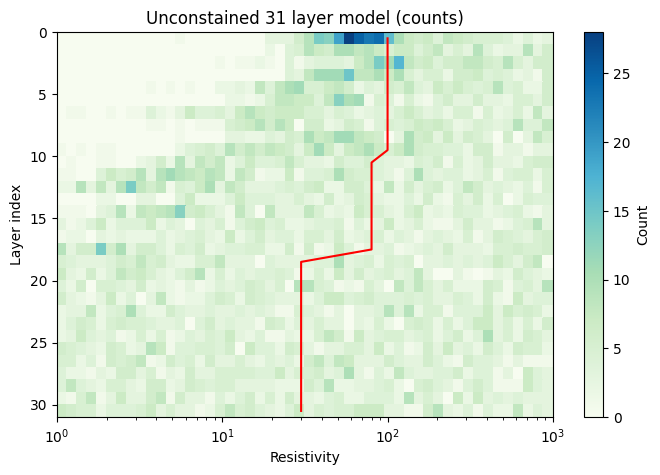

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# es.result: shape (n_sim, n_layers) = (300, 31)
res_vals = es0.good_models(threshold=np.inf)
n_sim, n_layers = res_vals.shape


res_bins = np.logspace(0, 3, 51)

n_bins = len(res_bins) - 1
pivot = np.zeros((n_bins, n_layers), dtype=int)

for j in range(n_layers):
    counts, _ = np.histogram(res_vals[:, j], bins=res_bins)
    pivot[:, j] = counts

print("pivot shape:", pivot.shape)  # (n_bins-1, 31)
print("bin edges shape:", res_bins.shape)

# Optional: visualize as a heatmap (y-axis = resistivity bins, x-axis = layer index)
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.pcolor(res_bins, np.arange(n_layers+1), pivot.T, cmap='GnBu')
ax.set_xscale('log')
ax.set_ylabel('Layer index')
ax.set_xlabel('Resistivity')
ax.set_title('Unconstained 31 layer model (counts)')
ax.plot(rho, np.arange(0, n_layers)+0.5, 'r-', label='True resistivity')
fig.colorbar(im, ax=ax, label='Count')
ax.invert_yaxis()
plt.show()

pivot shape: (50, 31)
bin edges shape: (51,)


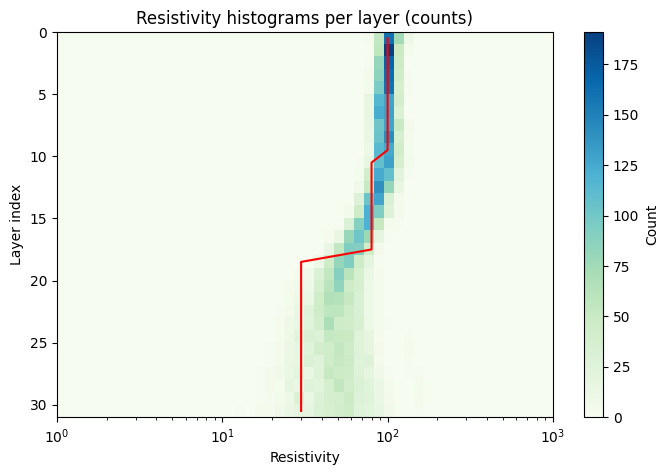

In [94]:
import numpy as np
import matplotlib.pyplot as plt

# es.result: shape (n_sim, n_layers) = (300, 31)
res_vals = es.good_models(threshold=np.inf)
n_sim, n_layers = res_vals.shape


res_bins = np.logspace(0, 3, 51)

n_bins = len(res_bins) - 1
pivot = np.zeros((n_bins, n_layers), dtype=int)

for j in range(n_layers):
    counts, _ = np.histogram(res_vals[:, j], bins=res_bins)
    pivot[:, j] = counts

print("pivot shape:", pivot.shape)  # (n_bins-1, 31)
print("bin edges shape:", res_bins.shape)

# Optional: visualize as a heatmap (y-axis = resistivity bins, x-axis = layer index)
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.pcolor(res_bins, np.arange(n_layers+1), pivot.T, cmap='GnBu')
ax.set_xscale('log')
ax.set_ylabel('Layer index')
ax.set_xlabel('Resistivity')
ax.set_title('Resistivity histograms per layer (counts)')
ax.plot(rho, np.arange(0, n_layers)+0.5, 'r-', label='True resistivity')
fig.colorbar(im, ax=ax, label='Count')
ax.invert_yaxis()
plt.show()